# 06 Sare neuronala (MLP) Kerasekin

Hurrengo orduko NO2a iragartzeko MLP sinple bat eraikiko dugu, hiperparametroak doituko ditugu eta 03 koadernoko eredu klasikoekin alderatuko dugu. Datu eta aurreprozesamendu berberak erabiltzen ditugu, alderaketa bidezkoa izan dadin.

MLPa geruza dentsoz osatutako sarea da: sarrera (65 zutabe) → Dense + ReLU → Dense + ReLU → irteera (neurona 1, NO2a µg/m3tan). Adam optimizatzailearekin eta MSE errorearekin entrenatzen dugu, eta dropout-a gaindoitzea (overfitting) saihesteko erabiltzen dugu.

In [1]:
# Liburutegiak
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"   # TensorFlow-en mezu gutxiago
import warnings
warnings.filterwarnings("ignore")

import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

import tensorflow as tf
from tensorflow import keras
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sys.path.append("../src")
from aurreprozesamendua import ERREGRESIO_HELBURUA

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 4)
print("TensorFlow", tf.__version__)

I0000 00:00:1795079024.304277    1352 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795079024.310043    1352 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1795079043.672684    1352 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795079043.675835    1352 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow 2.21.0


## 1. Datuak

PIAko aurreprozesadorea aplikatzen dugu (inputazioa, estandarizazioa eta one-hot). Kerasek entrenamenduaren azken % 20a balioztapenerako gordetzen du (validation_split=0.2); horrela hiperparametroak aukeratzen ditugu 2026a ukitu gabe.

In [2]:
entrenamendua = pd.read_csv("../data/prozesatuak/barakaldo_entrenamendua.csv", index_col="data", parse_dates=True)
proba = pd.read_csv("../data/prozesatuak/barakaldo_proba.csv", index_col="data", parse_dates=True)

aurreprozesadorea = joblib.load("../ereduak/aurreprozesadorea.joblib")
ALDAGAIAK = joblib.load("../ereduak/sarrera_aldagaiak.joblib")

X_entr = aurreprozesadorea.transform(entrenamendua[ALDAGAIAK]).astype("float32")
X_proba = aurreprozesadorea.transform(proba[ALDAGAIAK]).astype("float32")
y_entr = entrenamendua[ERREGRESIO_HELBURUA].values
y_proba = proba[ERREGRESIO_HELBURUA].values

n_zutabe = X_entr.shape[1]
print("X_entr:", X_entr.shape, "| X_proba:", X_proba.shape)
print("Balioztapena: noiztik", entrenamendua.index[int(len(entrenamendua) * 0.8)].date(), "noiz arte", entrenamendua.index[-1].date())

X_entr: (26039, 65) | X_proba: (7253, 65)
Balioztapena: noiztik 2025-05-27 noiz arte 2026-01-01


In [3]:
# MLP sinple bat sortzeko funtzioa
def mlp_sortu(geruzak, dropout, ikasketa_tasa=0.001):
    eredua = keras.Sequential()
    eredua.add(keras.Input(shape=(n_zutabe,)))
    for neuronak in geruzak:
        eredua.add(keras.layers.Dense(neuronak, activation="relu"))
        if dropout > 0:
            eredua.add(keras.layers.Dropout(dropout))
    eredua.add(keras.layers.Dense(1))
    eredua.compile(optimizer=keras.optimizers.Adam(ikasketa_tasa), loss="mse", metrics=["mae"])
    return eredua

def metrikak(y_benetakoa, y_iragarria):
    return (round(mean_absolute_error(y_benetakoa, y_iragarria), 3),
            round(float(np.sqrt(mean_squared_error(y_benetakoa, y_iragarria))), 3),
            round(r2_score(y_benetakoa, y_iragarria), 3))

## 2. Lehen eredua

Bi geruza ezkutu (64 eta 32 neurona), 0,2ko dropout-a eta 100 epoka. Ikasketa-kurbek esango digute zenbat epoka behar diren.

In [ ]:
#emaitza errepikagarria izateko
tf.keras.utils.set_random_seed(42)

mlp = mlp_sortu(geruzak=[64, 32], dropout=0.2)
mlp.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,337 (24.75 KB)

 Trainable params: 6,337 (24.75 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
hasiera = time.time()
historia = mlp.fit(X_entr, y_entr, validation_split=0.2, epochs=100, batch_size=64, verbose=0)
print("Denbora:", round(time.time() - hasiera, 1), "s")
print("Balioztapeneko MAE azken epokan:", round(historia.history["val_mae"][-1], 3))

Denbora: 71.2 s
Balioztapeneko MAE azken epokan: 3.859


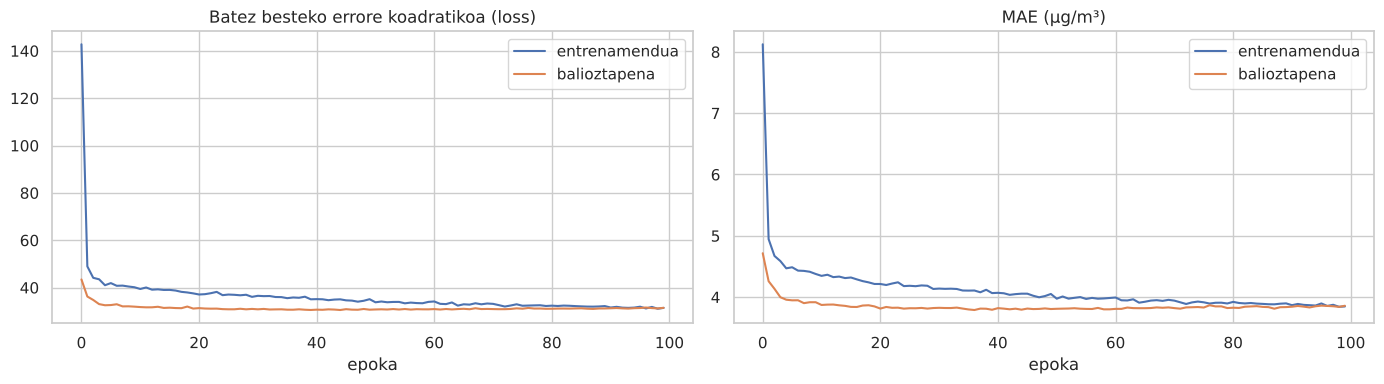

In [ ]:
# Ikasketa kurbak
fig, ardatzak = plt.subplots(1, 2, figsize=(14, 4))
ardatzak[0].plot(historia.history["loss"], label="entrenamendua")
ardatzak[0].plot(historia.history["val_loss"], label="balioztapena")
ardatzak[0].set_title("Batez besteko errore koadratikoa (loss)")
ardatzak[0].set_xlabel("epoka")
ardatzak[0].legend()
ardatzak[1].plot(historia.history["mae"], label="entrenamendua")
ardatzak[1].plot(historia.history["val_mae"], label="balioztapena")
ardatzak[1].set_title("MAE (µg/m³)")
ardatzak[1].set_xlabel("epoka")
ardatzak[1].legend()
plt.tight_layout()
plt.show()

Balioztapeneko errorea 20 epoka inguruan egonkortzen da (MAE ≈ 3,85) eta hortik aurrera ez da hobetzen. Entrenamendukoa altuagoa da dropout-a dela eta, eta poliki jaisten da. Ez dago gaindoitzerik, baina 100 epoka ez dira beharrezkoak: 50ekin nahikoa da eta denbora erdia behar du.

## 3. Hiperparametroen doikuntza

Hiru arkitektura eta bi dropout balio probatzen ditugu (6 konbinazio), denak 50 epokarekin eta balioztapen bera erabilita.

In [ ]:
#Ikasketa curben arabera
EPOKAK = 50

In [8]:
arkitekturak = [[32], [64, 32], [128, 64]]
dropout_balioak = [0.0, 0.2]

bilaketa = []
probatutako_ereduak = {}
for geruzak in arkitekturak:
    for dropout in dropout_balioak:
        tf.keras.utils.set_random_seed(42)
        eredua = mlp_sortu(geruzak, dropout)
        hasiera = time.time()
        h = eredua.fit(X_entr, y_entr, validation_split=0.2, epochs=EPOKAK, batch_size=64, verbose=0)
        izena = str(geruzak) + " dropout=" + str(dropout)
        probatutako_ereduak[izena] = eredua
        bilaketa.append([izena, eredua.count_params(), h.history["val_mae"][-1], time.time() - hasiera])
        print(izena, "-> balioztapen MAE:", round(h.history["val_mae"][-1], 3))

bilaketa_taula = pd.DataFrame(bilaketa, columns=["eredua", "parametroak", "balioztapen MAE", "denbora (s)"])
bilaketa_taula.sort_values("balioztapen MAE").round(3)

[32] dropout=0.0 -> balioztapen MAE: 3.838


[32] dropout=0.2 -> balioztapen MAE: 3.847


[64, 32] dropout=0.0 -> balioztapen MAE: 4.022


[64, 32] dropout=0.2 -> balioztapen MAE: 3.805


[128, 64] dropout=0.0 -> balioztapen MAE: 4.206


[128, 64] dropout=0.2 -> balioztapen MAE: 3.858


,eredua,parametroak,balioztapen MAE,denbora (s)
3,"[64, 32] dropout=0.2",6337,3.805,37.128
0,[32] dropout=0.0,2145,3.838,29.166
1,[32] dropout=0.2,2145,3.847,33.231
5,"[128, 64] dropout=0.2",16769,3.858,40.357
2,"[64, 32] dropout=0.0",6337,4.022,33.112
4,"[128, 64] dropout=0.0",16769,4.206,36.749


In [9]:
izen_onena = bilaketa_taula.sort_values("balioztapen MAE").iloc[0]["eredua"]
mlp_erregresioa = probatutako_ereduak[izen_onena]
print("Konfigurazio onena:", izen_onena)
mlp_erregresioa.summary()

Konfigurazio onena: [64, 32] dropout=0.2


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_10 (Dense)                │ (None, 64)             │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,013 (74.27 KB)

 Trainable params: 6,337 (24.75 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 12,676 (49.52 KB)

- Onena [64, 32] da 0,2ko dropout-arekin (balioztapen MAE 3,805), baina aldeak txikiak dira: sare txikienak ([32]) 3,84 lortzen du.
- Dropout-ak sare handienei laguntzen die. Hura gabe [64, 32] eta [128, 64] gaindoitzen hasten dira (4,02 eta 4,21).
- Neurona gehiago jartzeak ez du hobetzen; datuek ez dute horrenbesteko konplexutasunik eskatzen.

## 4. Ebaluazioa 2026ko datuekin

In [10]:
hasiera = time.time()
mlp_iragarpena = mlp_erregresioa.predict(X_proba, verbose=0).ravel()
print("2026 osoaren iragarpen-denbora:", round(time.time() - hasiera, 2), "s")

mae, rmse, r2 = metrikak(y_proba, mlp_iragarpena)
print("MLP -> MAE:", mae, "| RMSE:", rmse, "| R2:", r2)

2026 osoaren iragarpen-denbora: 0.3 s
MLP -> MAE: 4.116 | RMSE: 6.193 | R2: 0.775


In [ ]:
# SAAko emaitzak + MLP
alderaketa = pd.read_csv("../docs/emaitzak_erregresioa.csv")
alderaketa = alderaketa[["eredua", "proba MAE", "proba RMSE", "proba R2"]]
alderaketa.loc[len(alderaketa)] = ["MLP " + izen_onena, mae, rmse, r2]
alderaketa.round(3)

,eredua,proba MAE,proba RMSE,proba R2
0,Iraunkortasuna (baseline),4.554,7.010,0.712
1,Lineal sinplea (uneko NO2a),4.523,6.761,0.732
2,Lineal anizkoitza,4.263,6.314,0.766
3,Ridge (alpha=100),4.255,6.315,0.766
4,Lasso (alpha=0.01),4.242,6.314,0.766
5,Gehigarria: Random Forest,4.209,6.372,0.762
6,"MLP [64, 32] dropout=0.2",4.116,6.193,0.775


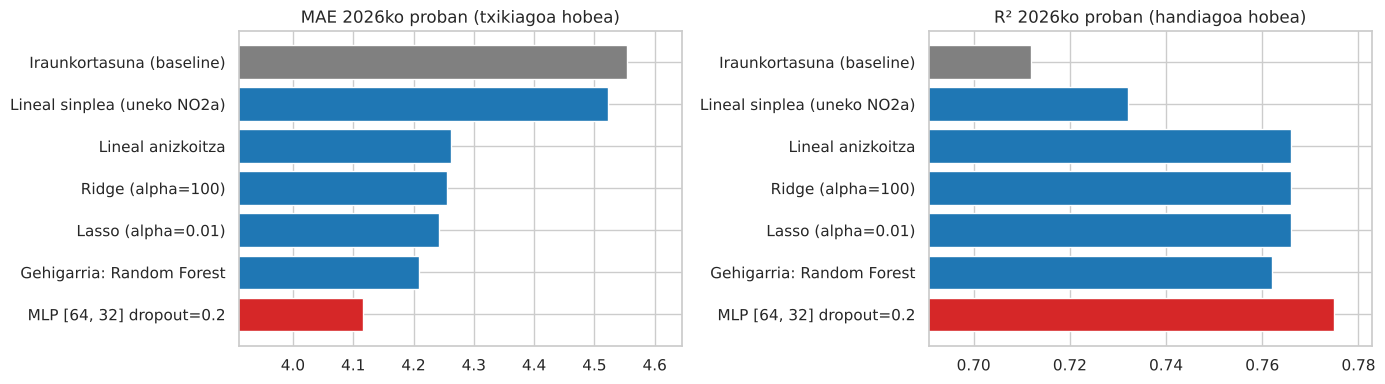

In [12]:
fig, ardatzak = plt.subplots(1, 2, figsize=(14, 4))
koloreak = ["tab:red" if izena.startswith("MLP") else ("gray" if "Iraunkortasuna" in izena else "tab:blue")
            for izena in alderaketa["eredua"]]
ardatzak[0].barh(alderaketa["eredua"], alderaketa["proba MAE"], color=koloreak)
ardatzak[0].set_xlim(alderaketa["proba MAE"].min() * 0.95, alderaketa["proba MAE"].max() * 1.02)
ardatzak[0].set_title("MAE 2026ko proban (txikiagoa hobea)")
ardatzak[0].invert_yaxis()
ardatzak[1].barh(alderaketa["eredua"], alderaketa["proba R2"], color=koloreak)
ardatzak[1].set_xlim(alderaketa["proba R2"].min() * 0.97, alderaketa["proba R2"].max() * 1.01)
ardatzak[1].set_title("R² 2026ko proban (handiagoa hobea)")
ardatzak[1].invert_yaxis()
plt.tight_layout()
plt.show()

In [13]:
# Erroreen alderaketa NO2 mailaren arabera (gailurrak dira garrantzitsuak alertetarako)
lasso = joblib.load("../ereduak/erregresio_onena_lasso.joblib")
lasso_iragarpena = lasso.predict(proba[ALDAGAIAK])

mailak = pd.cut(pd.Series(y_proba), bins=[0, 20, 40, 60, 100], labels=["0-20", "20-40", "40-60", ">60"])
erroreak = pd.DataFrame({
    "maila": mailak,
    "Lasso MAE": np.abs(y_proba - lasso_iragarpena),
    "MLP MAE": np.abs(y_proba - mlp_iragarpena),
    "Lasso alborapena": y_proba - lasso_iragarpena,
    "MLP alborapena": y_proba - mlp_iragarpena,
})
erroreak.groupby("maila", observed=True).mean().round(2)

,Lasso MAE,MLP MAE,Lasso alborapena,MLP alborapena
maila,,,,
0-20,3.22,3.00,-1.69,-1.60
20-40,5.18,5.13,2.14,2.42
40-60,8.95,9.30,7.11,8.04
>60,16.59,17.31,15.72,17.07


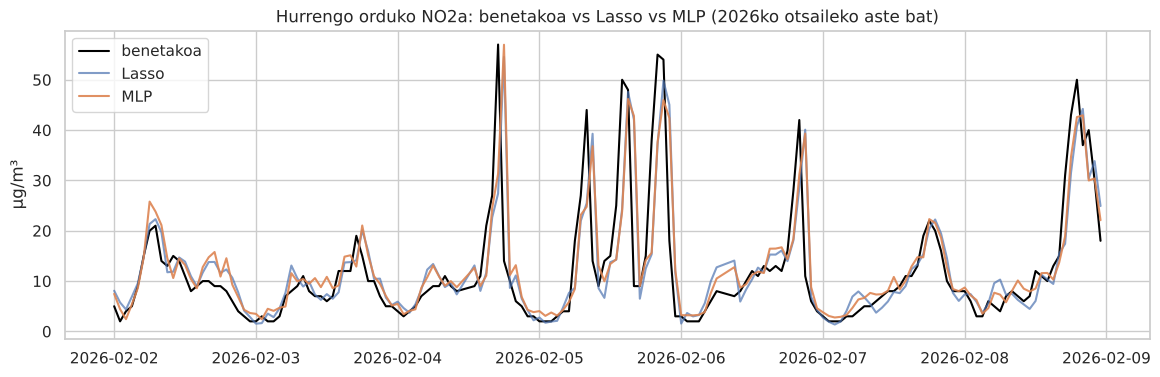

In [14]:
# 2026ko aste bat
astea = (proba.index >= "2026-02-02") & (proba.index < "2026-02-09")
plt.figure(figsize=(14, 4))
plt.plot(proba.index[astea], y_proba[astea], color="black", label="benetakoa")
plt.plot(proba.index[astea], lasso_iragarpena[astea], label="Lasso", alpha=0.7)
plt.plot(proba.index[astea], mlp_iragarpena[astea], label="MLP", alpha=0.9)
plt.title("Hurrengo orduko NO2a: benetakoa vs Lasso vs MLP (2026ko otsaileko aste bat)")
plt.ylabel("µg/m³")
plt.legend()
plt.show()

- MLPa da proban eredurik onena: MAE 4,12, Lassoren 4,24ren aldean (−% 3) eta Random Forestaren 4,21en aldean. R² 0,775 da.
- Hobekuntza txikia da. Eredu linealek ia dena hartzen dute dagoeneko, eta sareak ez-linealtasun gutxi aurkitzen du.
- NO2 baxuetan (0-20) hobeto dabil, baina gailurretan (> 60) Lassok bezala huts egiten du, are gehiago: 17 µg/m³ inguru labur geratzen da. Arazo bera da: gailurrak arraroak dira entrenamenduan.
- Abantaila: oso arina da (6.337 parametro, 27 KB .tflite), beraz Jetson Nanon arazorik gabe exekuta daiteke.

Ondorioz, MLPa erabiliko dugu hurrengo orduko NO2a iragartzeko, erabaki-zuhaitza ICA kategoriarako eta K-means uneko egoerarako.

## 5. MLPa gorde eta esportatu

- .keras: Kerasen formatua (PCan).
- .tflite: TensorFlow Lite, gailu txikietarako formatua.
- .npz: pisuak numpy matrize gisa, Jetsonen numpy-rekin bakarrik exekutatzeko (Jetsonek Python 3.6 du eta ezin du TensorFlow berria kargatu; ikus 07 koadernoa).

In [ ]:
os.makedirs("../jetson/ereduak", exist_ok=True)

# 1) Keras formatua
mlp_erregresioa.save("../ereduak/mlp_erregresioa_NO2.keras")

# 2) TensorFlow Lite
bihurgailua = tf.lite.TFLiteConverter.from_keras_model(mlp_erregresioa)
tflite_eredua = bihurgailua.convert()
with open("../jetson/ereduak/mlp_erregresioa_NO2.tflite", "wb") as fitxategia:
    fitxategia.write(tflite_eredua)

# 3)Geruza dentsoen pisuak numpy-n (dropout-ak ez du pisurik eta ez da erabiltzen iragartzean)
pisuak = {}
zenbakia = 0
for geruza in mlp_erregresioa.layers:
    if isinstance(geruza, keras.layers.Dense):
        W, b = geruza.get_weights()
        pisuak["W" + str(zenbakia)] = W
        pisuak["b" + str(zenbakia)] = b
        zenbakia += 1
np.savez("../jetson/ereduak/mlp_erregresioa_NO2_pisuak.npz", **pisuak)

print("Esportatutako geruza dentsoak:", zenbakia)
for izena in pisuak:
    print(" ", izena, pisuak[izena].shape)
print(".keras tamaina :", round(os.path.getsize("../ereduak/mlp_erregresioa_NO2.keras") / 1024, 1), "KB")
print(".tflite tamaina:", round(len(tflite_eredua) / 1024, 1), "KB")

INFO:tensorflow:Assets written to: /tmp/tmpuguv3756/assets


INFO:tensorflow:Assets written to: /tmp/tmpuguv3756/assets


Saved artifact at '/tmp/tmpuguv3756'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 65), dtype=tf.float32, name='keras_tensor_34')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  139660994871120: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139660994865936: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139660994870928: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139660994864400: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139660992127120: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139660992125008: TensorSpec(shape=(), dtype=tf.resource, name=None)


Esportatutako geruza dentsoak: 3
  W0 (65, 64)
  b0 (64,)
  W1 (64, 32)
  b1 (32,)
  W2 (32, 1)
  b2 (1,)
.keras tamaina : 103.5 KB
.tflite tamaina: 26.7 KB


In [16]:
# Egiaztapena: numpy-rekin "eskuz" exekutatutako sareak Kerasek bezala ematen du
def mlp_numpy(x, pisuak):
    n_geruza = len(pisuak) // 2
    for i in range(n_geruza):
        x = x @ pisuak["W" + str(i)] + pisuak["b" + str(i)]
        if i < n_geruza - 1:
            x = np.maximum(x, 0)   # ReLU geruza ezkutuetan
    return x.ravel()

aldea = np.abs(mlp_numpy(X_proba, pisuak) - mlp_iragarpena).max()
print("Alde maximoa numpy vs Keras:", aldea, "µg/m³")

# Eta gauza bera TensorFlow Lite-rekin
interpretatzailea = tf.lite.Interpreter(model_content=tflite_eredua)
interpretatzailea.allocate_tensors()
sarrera = interpretatzailea.get_input_details()[0]
irteera = interpretatzailea.get_output_details()[0]
tflite_iragarpena = []
for errenkada in X_proba[:500]:
    interpretatzailea.set_tensor(sarrera["index"], errenkada.reshape(1, -1))
    interpretatzailea.invoke()
    tflite_iragarpena.append(interpretatzailea.get_tensor(irteera["index"])[0, 0])
print("Alde maximoa TFLite vs Keras (500 ordu):", np.abs(np.array(tflite_iragarpena) - mlp_iragarpena[:500]).max(), "µg/m³")

alderaketa.to_csv("../docs/emaitzak_mlp_erregresioa.csv", index=False)

Alde maximoa numpy vs Keras: 7.6293945e-06 µg/m³
Alde maximoa TFLite vs Keras (500 ordu): 7.6293945e-06 µg/m³


INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
